# RQ3: preserving information and adapting Strands

**Question.** Can a fuller probability readout or targeted supervised adaptation improve usefulness?
This notebook separates the implemented readout experiment from the training study that still needs its runner and real B200 pilot. It never fits models or sends requests.

| View | Purpose |
|---|---|
| Regression input width | Show the extra columns required to retain the full probability distribution |
| Readout grid | Count new fits without repeating existing mean baselines |
| Adaptation grid | Distinguish four pilot training runs from the conditional 90-run study |

## 1. Scope and source identity

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.utils.config import load_yaml
from src.visualize import figures, style
from src.evaluation.research_questions import regression_width_table, regression_readout_plan, adaptation_plan
from src.visualize.research_questions import regression_width_figure
style.apply()
NOTEBOOK = "rq3/01_improvement_studies"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope and source identity")
display_json("Source", provenance())
record("No scientific improvement result is available here. Widths and fit counts describe the design, not performance.", "Evidence boundary")

## 2. How much information is lost by taking the mean?

All mass at the neutral level and equal mass at the two extremes both have mean zero. Retaining all nine coordinates distinguishes them. They have eight degrees of freedom; they are not eight additional questions. Missing text keeps the entire block missing.

dataset,text_columns,non_text_columns,joint_main,joint_probabilities,per_column_main,per_column_probabilities,both_main,both_probabilities,kumo_conservative_max
Baby Products,4,8,13,21,16,48,17,57,65
Book Price,5,3,9,17,13,53,14,62,65
Book Readability,6,24,31,39,36,84,37,93,117
Mercari Marketplace,6,3,10,18,15,63,16,72,75
Montgomery Salaries,3,8,12,20,14,38,15,47,55
Rotten Tomatoes,13,2,16,24,28,132,29,141,143
SciMagojr Impact,10,12,23,31,32,112,33,121,133
Vancouver Salaries,2,3,6,14,7,23,8,32,35
Video Games Sales,2,3,6,14,7,23,8,32,35


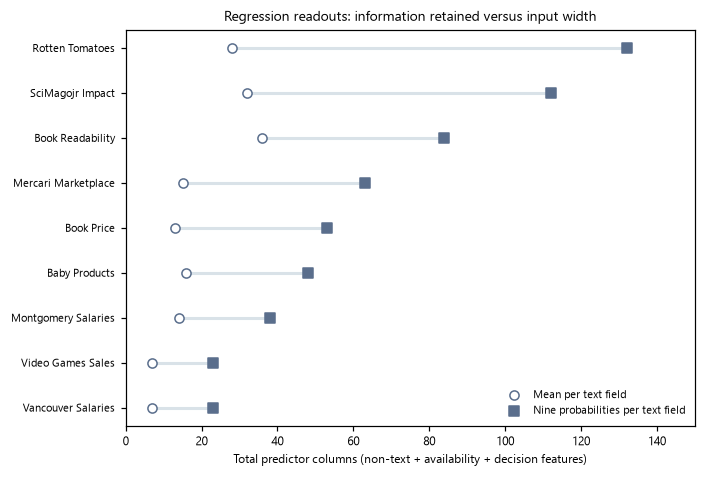

In [2]:
report_section("2. Regression representation width")
widths = regression_width_table()
display_table("Widths including non-text columns and availability flags", widths.drop(columns="dataset_id"), preview_rows=9)
fig = regression_width_figure(widths)
save(fig, "regression_readout_width", caption="Each line joins the mean and full nine-probability input widths for one regression dataset in the per-column mode. Counts include original non-text fields and one availability flag per text field, for a single extractor. No performance is plotted; the largest full-vector input has 132 columns before predictor-specific encoding.")
display_local(fig)
plt.close(fig)
record(widths, "Complete width audit")

## 3. Paired readout experiment

Linear and CatBoost use the same five folds and source feature blocks as their existing mean-feature baselines. Only the view changes. No winner is selected and no additional extraction is required.

In [3]:
report_section("3. New readout fits")
readout = pd.DataFrame(regression_readout_plan())
display_table("Readout configurations by predictor", readout.groupby("model").size().rename("configurations").reset_index())
record({"new_configurations": len(readout), "new_outer_fits": 5*len(readout), "new_model_requests": 0, "execution_enabled": load_yaml("rq3/readout")["enabled"]}, "Readout budget")

model,configurations
catboost,117
linear,117


## 4. What adaptation will test

Strands 2B is a controlled case study: original versus temperature scaling, head-only training and LoRA plus head. Begin with one fold of Jigsaw and Product Sentiment. Expand only after the training runner, split isolation, gradients, adapter replay and B200 pilot pass. These are direct classification predictions; a later downstream stacking study would require extra cross-fitting and is excluded.

In [4]:
report_section("4. Adaptation readiness and counts")
adaptation = pd.DataFrame(adaptation_plan())
display_table("Training plan by variant", adaptation.groupby("variant").agg(training_runs=("fold","size"), pilot_runs=("pilot","sum")).reset_index())
record(load_yaml("rq3/adaptation"), "Adaptation design and outstanding gates")
record(load_yaml("experiment_0/research_questions"), "Required qualification coverage")

variant,training_runs,pilot_runs
head_only,45,2
lora_and_head,45,2


## Complete printed report

The complete tables and qualification state follow, including the distinction between implemented readouts and planned training.

In [5]:
finish_report(NOTEBOOK, save.summary() + "\nNo adaptation, inference or benchmark was executed.")

rq3/01_improvement_studies

1. Scope and source identity


Source
{
  "code_sha256": "76ade2f7051f3417b081ae23a5792bd608dfd0f2037a6ff6247be99729aa9bad",
  "git_head": "a9fbd4331732f0c8e20b3802342c01ec4977cf06",
  "git_dirty": true,
  "tfm_library_pin": "43d4938e50fab660d942d4b79cbaca61544c27cf dm-library (remotes/origin/HEAD)\n c08b03530c4f0f9019cd1cd59e749c97dabcbfac tfm-library (remotes/origin/HEAD)\n 710d1c3e0cd5f153a7d5eafcf83f6d51703c1bf6 vsc-library (heads/main-1-g710d1c3)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


Evidence boundary
No scientific improvement result is available here. Widths and fit counts describe the design, not performance.


2. Regression representation width


Widths including non-text columns and availability flags
            dataset  text_columns  non_text_columns  joint_main  joint_probabilities  per_column_main  per_column_pr